# Which PSX sectors paid best for the risk?

**Question.** Over the five years from 2021-10-27 to 2026-10-27, which sectors of the Pakistan Stock Exchange gave the best return for the risk?

**Approach.** Each sector is an equal-weighted portfolio (rebalanced monthly, dividends included) of its companies that trade regularly (209 companies, 22 ranked sectors). Risk is measured by volatility and by the worst fall from a peak; return per unit of risk by the Sharpe ratio, taking cash at the State Bank's policy rate as the safe alternative.

**Short answer.** By Sharpe ratio the leading sector is **Fertilizer** (1.25, 95% range 0.36 to 2.20) against 0.40 for the whole market. It comes first in 54% of resampled histories, so the top group is a shortlist, not a winner.

**Beyond the ranking.** Sections 8 to 10 ask whether the leaders earned their record by skill or by luck, what moves the sectors, and whether the ranking could have been used.

This notebook uses only the results committed in `data/processed`, so it runs without downloading anything. The full pipeline (`python -m psxsec all`) rebuilds them from the raw prices. Nothing here is investment advice.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from psxsec import analysis, metrics  # noqa: E402  (the same functions the pipeline uses)

P = ROOT / "data" / "processed"
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

summary = json.loads((P / "summary.json").read_text())
table = pd.read_csv(P / "sector_summary.csv", dtype={"sector_code": str})
daily = pd.read_csv(P / "sector_daily_returns.csv", index_col=0, parse_dates=True)
safe = daily.pop("Safe return (policy rate)")
ranked = table[table["ranked"]].sort_values("sharpe", ascending=False).reset_index(drop=True)
market = table[table["sector"] == "Whole market"].iloc[0]
years = summary["window"]["years"]
ppy = len(daily) / years
print(f"{len(daily):,} market days, {summary['window']['base_date']} to {summary['window']['end_date']} ({years:.2f} years)")

1,227 market days, 2021-10-27 to 2026-10-27 (5.00 years)


## 1. Who is in the analysis

Every company in the KSE All Share Index, minus investment funds, ETFs and property trusts. A company qualifies if it has a price on nearly every market day of the five years and traded on at least 90% of them. The rule removes stocks whose price hardly ever changes because few trades happen: they can look safer than they are.

In [2]:
funnel = pd.read_csv(P / "universe_funnel.csv")
funnel

,step,companies
0,"Listings on the PSX data portal (shares, right...",752
1,In the KSE All Share Index,549
2,"Operating companies (funds, ETFs and REITs rem...",538
3,Prices found on Yahoo Finance,435
4,A price on nearly every market day of the five...,422
5,Traded on at least 90% of market days (qualify),209


In [3]:
status = pd.read_csv(P / "stock_status.csv", dtype={"sector_code": str})
sizes = status.groupby("sector")["status"].value_counts().unstack(fill_value=0)
sizes["total"] = sizes.sum(axis=1)
sizes.sort_values("qualifies", ascending=False)

status,listed after the start of the window,no prices on Yahoo Finance,prices missing on too many days,qualifies,traded on too few days,total
sector,,,,,,
Commercial banks,0,1,0,16,2,19
Cement,0,1,0,15,3,19
Chemicals,1,4,0,14,8,27
Food and personal care,0,7,0,14,7,28
Technology and communication,1,9,0,13,0,23
Engineering,0,1,0,12,4,17
Power generation and distribution,0,3,0,11,1,15
Investment banks and securities,5,10,1,11,11,38
Textile composite,0,10,0,10,26,46


## 2. How a sector index is built

A sector index holds equal amounts of each of its companies on the first day of every month and lets the holdings drift with prices until the next month; its daily return is the change in value (price change plus dividends). A small company counts as much as a large one at the start of each month. Putting the weights back to equal every day, which is the plain average of the companies' returns, would flatter shares that trade rarely, so the monthly version is used.

In [4]:
# Three made-up companies over four days in the same month.
toy = pd.DataFrame({"A": [0.02, -0.01, 0.00, 0.03], "B": [0.00, 0.01, -0.02, 0.01], "C": [0.04, -0.03, 0.01, 0.00]},
                   index=pd.bdate_range("2024-01-01", periods=4))
toy["rebalanced every day (plain average)"] = analysis.equal_weight_return(toy[["A", "B", "C"]], rebalance="D")
toy["rebalanced monthly (used here)"] = analysis.equal_weight_return(toy[["A", "B", "C"]], rebalance="M")
toy  # the two agree on the first day of the month, then the monthly version lets the holdings drift

,A,B,C,rebalanced every day (plain average),rebalanced monthly (used here)
2024-01-01,0.020,0.000,0.040,0.020,0.020
2024-01-02,-0.010,0.010,-0.030,-0.010,-0.010
2024-01-03,0.000,-0.020,0.010,-0.003,-0.003
2024-01-04,0.030,0.010,0.000,0.013,0.013


## 3. The measures

The functions in `psxsec/metrics.py` compute them. As a check, the cell below recomputes the leading sector's numbers from its daily returns and compares them with the results table.

In [5]:
# Recompute one sector's measures from its daily returns and check them against the results table.
name = ranked.loc[0, "sector"]
r = daily[name]
level = pd.concat([pd.Series([100.0], index=[pd.Timestamp(summary["window"]["base_date"])]), metrics.cumulative(r)])
recomputed = {
    "return a year": metrics.annualised_return(r, years),
    "volatility": metrics.volatility(r, ppy),
    "worst fall": metrics.max_drawdown(level)["max_drawdown"],
    "Sharpe ratio": metrics.sharpe(r - safe, ppy),
}
row = ranked.loc[0]
stored = {"return a year": row["cagr"], "volatility": row["volatility"], "worst fall": row["max_drawdown"], "Sharpe ratio": row["sharpe"]}
check = pd.DataFrame({"recomputed here": recomputed, "in the results table": stored})
assert np.allclose(check["recomputed here"], check["in the results table"], atol=1e-4), check
print(name)
check

Fertilizer


,recomputed here,in the results table
return a year,0.561,0.561
volatility,0.263,0.263
worst fall,-0.324,-0.324
Sharpe ratio,1.252,1.252


## 4. The results

Sectors ranked by Sharpe ratio. 'Chance of top 3' and 'chance better than market' come from the resampling in section 6.

In [6]:
columns = ["sector", "n_companies", "cagr", "volatility", "max_drawdown", "sharpe", "sharpe_lo", "sharpe_hi", "p_top3", "p_beats_market"]
shown = ranked[columns].rename(columns={"n_companies": "companies", "cagr": "return a year", "max_drawdown": "worst fall", "sharpe_lo": "sharpe 2.5%",
                                        "sharpe_hi": "sharpe 97.5%", "p_top3": "chance of top 3", "p_beats_market": "chance better than market"})
shown.index = shown.index + 1
shown

,sector,companies,return a year,volatility,worst fall,sharpe,sharpe 2.5%,sharpe 97.5%,chance of top 3,chance better than market
1,Fertilizer,4,0.561,0.263,-0.324,1.252,0.355,2.195,0.847,0.982
2,Commercial banks,16,0.419,0.219,-0.241,1.018,-0.014,2.023,0.643,0.973
3,Power generation and distribution,11,0.392,0.240,-0.311,0.868,-0.155,1.887,0.443,0.888
4,Oil and gas exploration,4,0.352,0.257,-0.307,0.715,-0.125,1.506,0.246,0.788
5,Automobile assemblers,8,0.329,0.254,-0.288,0.650,-0.346,1.636,0.197,0.731
6,Refinery,4,0.339,0.424,-0.418,0.542,-0.324,1.407,0.129,0.631
7,Transport,4,0.305,0.311,-0.344,0.524,-0.446,1.474,0.114,0.615
8,Cement,15,0.294,0.306,-0.480,0.500,-0.396,1.400,0.068,0.645
9,Insurance,7,0.280,0.283,-0.323,0.480,-0.401,1.383,0.067,0.589
10,Investment banks and securities,11,0.296,0.360,-0.535,0.479,-0.445,1.498,0.111,0.572


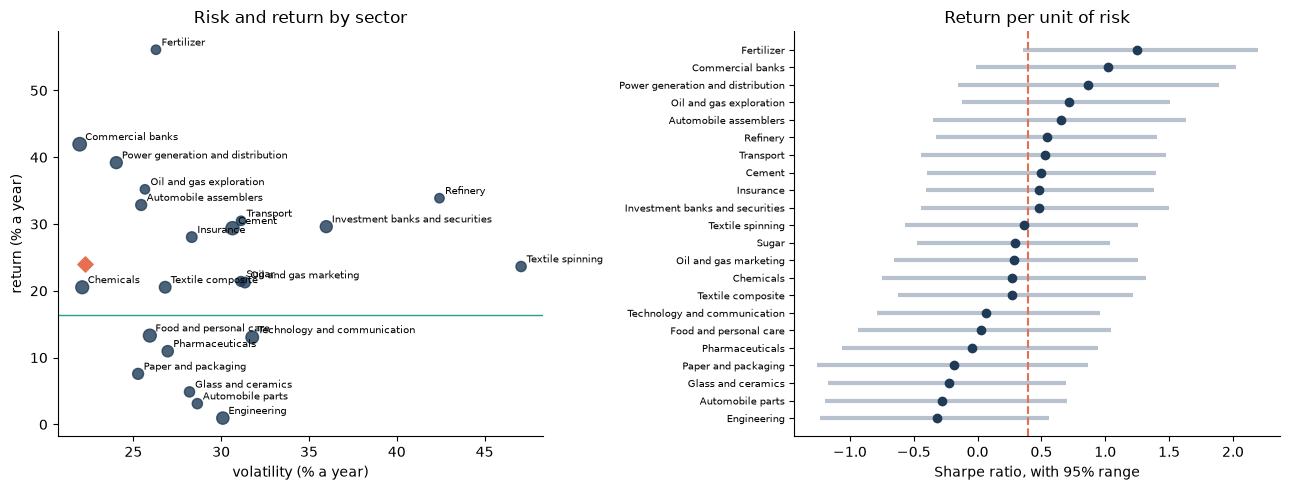

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(ranked["volatility"] * 100, ranked["cagr"] * 100, s=30 + 4 * ranked["n_companies"], color="#1F3B57", alpha=0.8)
for _, r_ in ranked.iterrows():
    ax.annotate(r_["sector"], (r_["volatility"] * 100, r_["cagr"] * 100), xytext=(4, 3), textcoords="offset points", fontsize=7)
ax.scatter(market["volatility"] * 100, market["cagr"] * 100, marker="D", color="#E76F51", s=60)
ax.axhline(summary["safe"]["cagr"] * 100, color="#2A9D8F", lw=1)
ax.set_xlabel("volatility (% a year)")
ax.set_ylabel("return (% a year)")
ax.set_title("Risk and return by sector")
ax = axes[1]
s = ranked.sort_values("sharpe")
ax.hlines(range(len(s)), s["sharpe_lo"], s["sharpe_hi"], color="#B8C2CF", lw=3)
ax.scatter(s["sharpe"], range(len(s)), color="#1F3B57", zorder=3)
ax.axvline(market["sharpe"], color="#E76F51", ls="--")
ax.set_yticks(range(len(s)), s["sector"], fontsize=7)
ax.set_xlabel("Sharpe ratio, with 95% range")
ax.set_title("Return per unit of risk")
plt.tight_layout()
plt.show()

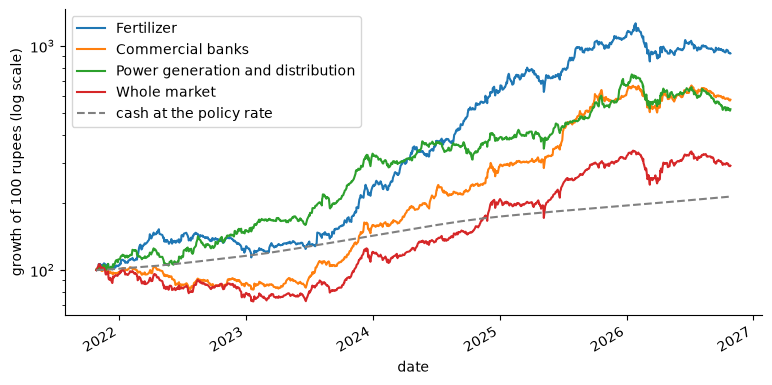

In [8]:
top3 = ranked["sector"].head(3).tolist()
levels = 100 * (1 + daily[[*top3, "Whole market"]]).cumprod()
cash = 100 * (1 + safe).cumprod()
ax = levels.plot(figsize=(9, 4.5), logy=True)
cash.plot(ax=ax, color="grey", ls="--", label="cash at the policy rate")
ax.set_ylabel("growth of 100 rupees (log scale)")
ax.legend()
plt.show()

## 5. Ups and downs

The figures in `docs/figures` show the worst fall of each sector, the year-by-year returns and how much of the return came from dividends. The interactive dashboard has the same views for every sector.

## 6. How sure can we be?

Five years is one history. To see how much the ranking depends on luck, the days are resampled in blocks of about 10 (to keep short streaks together) and the Sharpe ratio recomputed. Doing this for all sectors at once gives each sector's chance of finishing first or in the top three.

Fertilizer: Sharpe 1.25; 95% range from 500 resamples 0.48 to 2.21; pipeline (2,000 resamples) 0.36 to 2.20


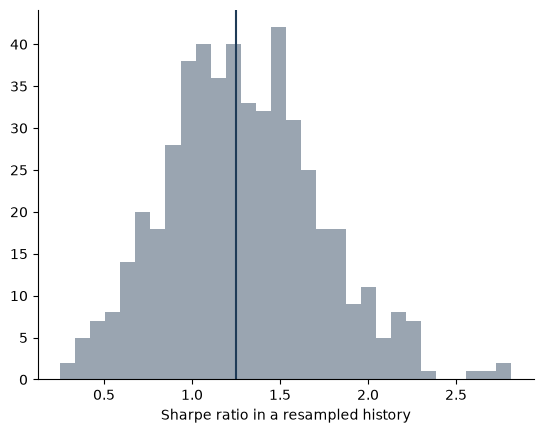

In [9]:
config_block = 10
# Resample the days in blocks of about 10 and recompute the Sharpe ratio each time (500 resamples here, 2,000 in the pipeline).
excess = (daily[[name]].sub(safe, axis=0))
draws = metrics.bootstrap_sharpe(excess, ppy, draws=500, mean_block=config_block, seed=1)[:, 0]
print(f"{name}: Sharpe {row['sharpe']:.2f}; 95% range from 500 resamples {np.percentile(draws, 2.5):.2f} to {np.percentile(draws, 97.5):.2f}; "
      f"pipeline (2,000 resamples) {row['sharpe_lo']:.2f} to {row['sharpe_hi']:.2f}")
plt.hist(draws, bins=30, color="#9AA5B1")
plt.axvline(row["sharpe"], color="#1F3B57")
plt.xlabel("Sharpe ratio in a resampled history")
plt.show()

In [10]:
distribution = pd.read_csv(P / "sector_rank_distribution.csv", index_col=0)
top = distribution.loc[ranked["sector"].head(6)].iloc[:, :6]
top.columns = ["first" if c == "rank_1" else c.replace("rank_", "position ") for c in top.columns]
top  # the share of resampled histories in which each sector finished in each of the top positions

,first,position 2,position 3,position 4,position 5,position 6
sector,,,,,,
Fertilizer,0.537,0.200,0.109,0.064,0.035,0.018
Commercial banks,0.177,0.276,0.191,0.127,0.071,0.052
Power generation and distribution,0.130,0.159,0.154,0.128,0.094,0.080
Oil and gas exploration,0.032,0.098,0.117,0.131,0.123,0.101
Automobile assemblers,0.034,0.067,0.096,0.108,0.110,0.090
Refinery,0.025,0.038,0.065,0.074,0.080,0.088


## 7. Do other choices change the answer?

The analysis was repeated using only KSE-100 companies, looser and tighter trading rules, rebalancing every day, weekly instead of daily returns, dropping each sector's best company, leaving out companies whose prices were corrected, the typical company instead of the average, each half of the window, and trimming three months from either end. 'Rank correlation' is 1 when a choice gives the same order as the main result.

In [11]:
robust = pd.read_csv(P / "robustness_summary.csv")
robust

,choice,kind,sectors_compared,rank_correlation,top3_in_common,top_tested,same_top_sector,main_top_sector_still_top3
0,KSE-100 companies only,method,11,0.982,3,True,True,True
1,Must trade on 80% of days,method,22,0.879,3,True,True,True
2,Must trade on 95% of days,method,21,0.996,3,True,True,True
3,Without companies with price corrections,method,17,0.973,3,False,False,False
4,Rebalanced every day,method,22,0.967,3,True,True,True
5,Weekly returns,method,22,0.990,3,True,True,True
6,Without each sector's best company,method,22,0.962,3,True,True,True
7,Typical company (median),method,22,0.925,2,True,True,True
8,First half of the window,period,22,0.826,2,True,True,True
9,Second half of the window,period,22,0.605,1,True,False,False


In [12]:
sharpes = pd.read_csv(P / "robustness_sharpe.csv", index_col=0).loc[ranked["sector"]]
sharpes.rank(ascending=False, method="min").astype("Int64")

,Main result,KSE-100 companies only,Must trade on 80% of days,Must trade on 95% of days,Without companies with price corrections,Rebalanced every day,Weekly returns,Without each sector's best company,Typical company (median),First half of the window,Second half of the window,Start 3 months later,End 3 months earlier
sector,,,,,,,,,,,,,
Fertilizer,1,1,1,1,<NA>,1,1,1,1,1,6,1,1
Commercial banks,2,2,2,2,1,2,2,2,2,4,2,2,2
Power generation and distribution,3,3,3,3,3,3,3,3,5,2,17,3,3
Oil and gas exploration,4,5,4,4,<NA>,4,4,4,3,5,8,4,5
Automobile assemblers,5,4,13,5,2,6,5,5,11,3,18,5,4
Refinery,6,<NA>,9,6,4,7,7,6,4,6,9,7,10
Transport,7,<NA>,12,7,<NA>,12,9,14,13,9,3,6,9
Cement,8,6,7,9,6,9,8,7,7,10,4,8,6
Insurance,9,<NA>,6,8,<NA>,5,6,8,6,8,11,10,7


## 8. Skill or luck?

A sector can rank high because it moves with a rising market, or because it carries little of the market's risk. Each sector's weekly return above cash is set against the weekly return of the rest of the market (every company outside that sector): **beta** is how strongly it follows that market and **alpha** is the return a year that is left over. Sectors with a lower beta tended to have the higher Sharpe ratio (rank correlation -0.52), and all of the top three are among the five lowest-beta sectors. That describes these five years, in which the whole market's Sharpe ratio was 0.40.

**No sector's alpha holds up once all 22 are tested together.** Tested one at a time, 5 of the 22 sectors look real (2 positive, 3 negative). The best of 22 sectors looks good by chance, so the p-values are corrected for having looked at all of them (with no real alpha anywhere, the largest t-statistic among 22 would still exceed 3.11 one time in twenty). On the looser false-discovery-rate rule, which accepts that a small share of findings may be false, Engineering (-21% a year) clears the bar.

In [13]:
from psxsec import config, stats  # noqa: E402

# Recompute the best sector's beta and alpha from its weekly returns against the rest of the market, and check them against the results table.
rest = pd.read_csv(P / "market_excluding_sector_daily_returns.csv", index_col=0, parse_dates=True)
best = summary["alpha"]["best_sector"]
week_sector, week_safe = analysis.weekly(daily[[best]], safe)
week_rest, _ = analysis.weekly(rest[[best]], safe)
fit = stats.market_model((week_sector[best] - week_safe).to_numpy(), (week_rest[best] - week_safe).to_numpy(), config.HAC_LAGS_WEEKLY)
weeks_per_year = len(week_safe) / years
stored = table.set_index("sector").loc[best]
check = pd.DataFrame({"recomputed here": {"beta": fit["beta"], "alpha a year": fit["alpha"] * weeks_per_year, "t of alpha": fit["alpha_t"]},
                      "in the results table": {"beta": stored["beta"], "alpha a year": stored["alpha"], "t of alpha": stored["alpha_t"]}})
assert np.allclose(check["recomputed here"], check["in the results table"], atol=1e-3), check
print(best)
check

Fertilizer


,recomputed here,in the results table
beta,0.589,0.589
alpha a year,0.282,0.282
t of alpha,2.731,2.731


In [14]:
columns = ["sector", "beta", "alpha", "alpha_t", "alpha_p", "alpha_p_adjusted", "dsr"]
skill = ranked[columns].sort_values("alpha_p").rename(columns={"alpha": "alpha a year", "alpha_t": "t", "alpha_p": "p alone",
                                                              "alpha_p_adjusted": "p corrected", "dsr": "deflated Sharpe"})
skill.reset_index(drop=True).head(8)  # the eight strongest cases; 'p corrected' allows for having looked at every ranked sector

,sector,beta,alpha a year,t,p alone,p corrected,deflated Sharpe
0,Engineering,1.152,-0.206,-3.591,0.000,0.060,0.006
1,Fertilizer,0.589,0.282,2.731,0.006,0.087,0.838
2,Glass and ceramics,1.041,-0.166,-2.409,0.016,0.544,0.010
3,Commercial banks,0.690,0.171,2.357,0.018,0.359,0.677
4,Automobile parts,1.084,-0.171,-2.275,0.023,0.505,0.007
5,Paper and packaging,0.973,-0.135,-1.765,0.078,0.793,0.013
6,Power generation and distribution,0.818,0.146,1.665,0.096,0.809,0.547
7,Oil and gas exploration,0.698,0.123,1.536,0.125,0.956,0.411


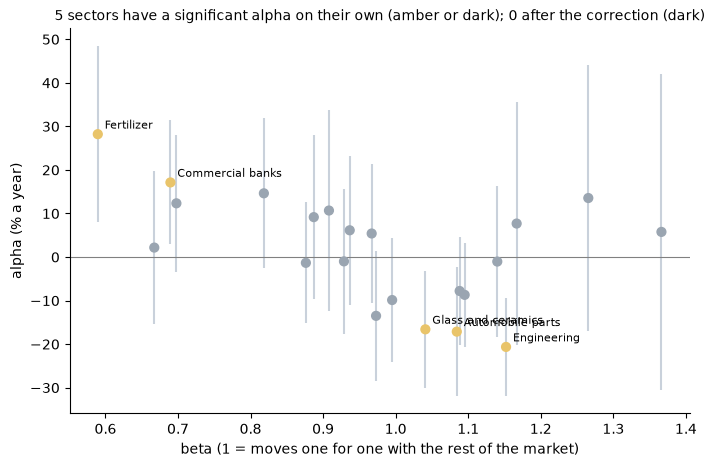

In [15]:
alone, corrected = int((ranked["alpha_p"] < 0.05).sum()), int((ranked["alpha_p_adjusted"] < 0.05).sum())
colour = np.where(ranked["alpha_p_adjusted"] < 0.05, "#1F3B57", np.where(ranked["alpha_p"] < 0.05, "#E9C46A", "#9AA5B1"))
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(ranked["beta"], ranked["alpha"] * 100, yerr=1.96 * ranked["alpha_se"] * 100, fmt="none", ecolor="#C9D1DB", zorder=1)
ax.scatter(ranked["beta"], ranked["alpha"] * 100, c=colour, s=40, zorder=3)
for _, r_ in ranked.iterrows():
    if r_["alpha_p"] < 0.05:
        ax.annotate(r_["sector"], (r_["beta"], r_["alpha"] * 100), xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("beta (1 = moves one for one with the rest of the market)")
ax.set_ylabel("alpha (% a year)")
ax.set_title(f"{alone} sectors have a significant alpha on their own (amber or dark); {corrected} after the correction (dark)", fontsize=10)
plt.show()

In [16]:
a = summary["alpha"]
print(f"With no skill, the best of {a['trials']} sectors would be expected to reach a Sharpe ratio of about {a['expected_best_sharpe']:.2f}; "
      f"the best actual one is {ranked.loc[0, 'sharpe']:.2f}.")
print(f"Deflated Sharpe ratio of {a['best_dsr_sector']}: {a['best_dsr']:.2f} (0.95 would be convincing); {a['n_dsr_95']} sectors reach it.")

With no skill, the best of 22 sectors would be expected to reach a Sharpe ratio of about 0.81; the best actual one is 1.25.
Deflated Sharpe ratio of Fertilizer: 0.84 (0.95 would be convincing); 0 sectors reach it.


## 9. What moves the sectors?

60% of the variation in sector returns is one market-wide movement, so the 22 sectors behave like 2.8 independent bets. With the market taken out, the average correlation between two sectors falls from 0.57 to -0.04; the strongest remaining link is Oil and gas exploration with Oil and gas marketing (0.28). Tested together, 0 of the 22 sectors react clearly to interest rates and 1 to the rupee (Automobile assemblers).

The groups come from clustering the correlations that remain after the market is taken out of each sector; they describe these five years and are not a classification. The last table shows the sectors with a significant interest-rate or rupee effect when tested one at a time, with the p-value corrected for testing every sector.

The first component carries 60% of the variation, so the 22 sectors behave like 2.8 independent bets.


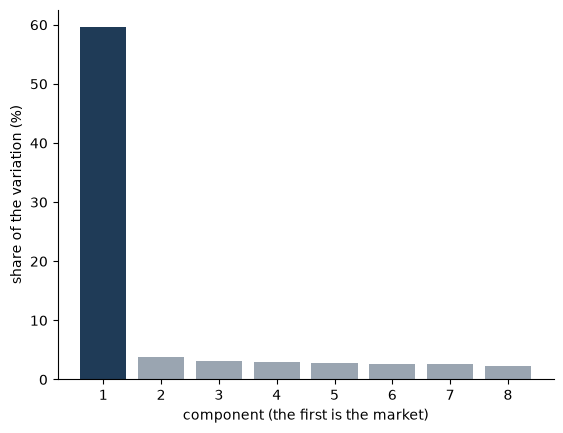

In [17]:
from psxsec import portfolios  # noqa: E402

sectors = ranked["sector"].tolist()
components = portfolios.principal_components(daily[sectors].sub(safe, axis=0))
st = summary["structure"]
assert np.isclose(components["share"][0], st["pc1_share"], atol=1e-4) and np.isclose(components["effective_bets"], st["effective_bets"], atol=1e-3)
print(f"The first component carries {components['share'][0]:.0%} of the variation, so the {len(sectors)} sectors behave like "
      f"{components['effective_bets']:.1f} independent bets.")
plt.bar(range(1, 9), components["share"][:8] * 100, color=["#1F3B57"] + ["#9AA5B1"] * 7)
plt.xlabel("component (the first is the market)")
plt.ylabel("share of the variation (%)")
plt.show()

In [18]:
pd.DataFrame({"group": [config.GROUP_LETTERS[i] for i in range(len(st["groups"]))], "sectors": [", ".join(g) for g in st["groups"]]})

,group,sectors
0,A,"Sugar, Investment banks and securities, Textil..."
1,B,"Cement, Engineering, Textile composite, Chemic..."
2,C,"Insurance, Power generation and distribution, ..."
3,D,"Transport, Pharmaceuticals, Automobile assembl..."


In [19]:
macro_columns = ["sector", "rate_beta", "rate_p", "rate_q", "fx_beta", "fx_p", "fx_q"]
macro = ranked[macro_columns].assign(best_p=ranked[["rate_p", "fx_p"]].min(axis=1)).sort_values("best_p").head(6).drop(columns="best_p")
macro.rename(columns={"rate_beta": "% per point of policy rate", "fx_beta": "% per 1% weaker rupee", "rate_q": "rate p corrected", "fx_q": "rupee p corrected",
                      "rate_p": "rate p", "fx_p": "rupee p"}).reset_index(drop=True)

,sector,% per point of policy rate,rate p,rate p corrected,% per 1% weaker rupee,rupee p,rupee p corrected
0,Automobile assemblers,1.398,0.030,0.217,-0.513,0.000,0.000
1,Sugar,1.488,0.013,0.141,0.053,0.572,0.859
2,Pharmaceuticals,-2.136,0.013,0.141,-0.111,0.419,0.859
3,Textile composite,1.450,0.045,0.227,0.027,0.797,0.894
4,Investment banks and securities,-2.021,0.052,0.227,0.142,0.335,0.859
5,Cement,-1.085,0.087,0.297,-0.148,0.138,0.759


## 10. Could the ranking have been used?

On the last day of each month a rule sees only the previous 12 months and chooses the weights for the next. That gives 48 months of results, from 2022-11, that the rule could not have known in advance. **The past ranking beat equal weighting out of sample, but not by more than luck could give.** Holding the 3 sectors with the best past Sharpe ratio gave a Sharpe ratio of 1.37 against 0.87 for equal weights (p = 0.070; 0.350 after allowing for five comparisons). On average the past ranking pointed the right way, but only weakly. Weights chosen to make the portfolio as steady as possible gave a volatility of 19% against 23% and a Sharpe ratio of 1.35 against 0.87. The gain in Sharpe ratio is significant on its own (p = 0.018) but not after allowing for the five comparisons made (p = 0.090).

48 months tested, from 2022-11-01; the rule reproduces the stored returns


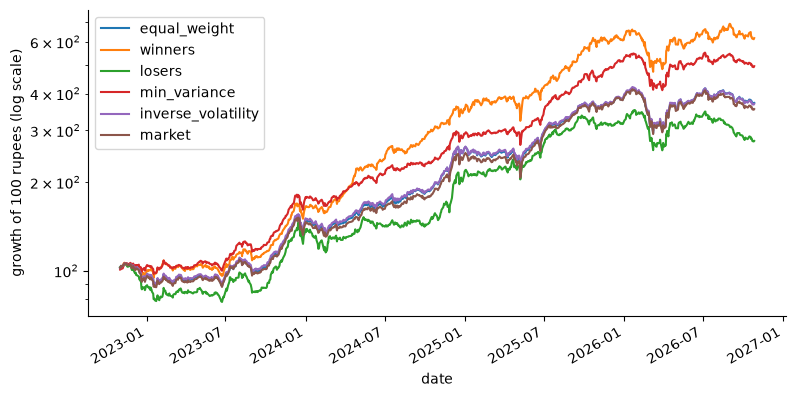

In [20]:
# Run the "best sectors of the past year" rule again from the committed daily returns and check it against the stored result.
wf = summary["walk_forward"]
again = portfolios.walk_forward(daily[sectors], safe, {"winners": portfolios.top_sharpe_rule(wf["top_sectors"])}, wf["lookback_months"],
                                pd.Timestamp(summary["window"]["base_date"]))
stored = pd.read_csv(P / "walk_forward_daily_returns.csv", index_col=0, parse_dates=True)
assert np.allclose(again["returns"]["winners"], stored["winners"], atol=1e-5)
print(f"{wf['months']} months tested, from {stored.index[0].date()}; the rule reproduces the stored returns")
ax = (100 * (1 + stored).cumprod()).plot(figsize=(9, 4.5), logy=True)
ax.set_ylabel("growth of 100 rupees (log scale)")
plt.show()

In [21]:
pd.read_csv(P / "walk_forward_summary.csv", index_col="strategy")[["cagr", "volatility", "max_drawdown", "sharpe", "sharpe_vs_equal",
                                                                "vs_equal_lo", "vs_equal_hi", "vs_equal_p", "vs_equal_p_adjusted"]]

,cagr,volatility,max_drawdown,sharpe,sharpe_vs_equal,vs_equal_lo,vs_equal_hi,vs_equal_p,vs_equal_p_adjusted
strategy,,,,,,,,,
equal_weight,0.392,0.227,-0.294,0.865,0.000,NaN,NaN,NaN,NaN
winners,0.581,0.239,-0.281,1.372,0.507,-0.050,1.094,0.070,0.350
losers,0.291,0.245,-0.271,0.513,-0.352,-0.838,0.051,0.103,0.515
min_variance,0.496,0.194,-0.250,1.355,0.490,0.102,0.922,0.018,0.090
inverse_volatility,0.389,0.221,-0.291,0.874,0.009,-0.041,0.057,0.685,1.000
market,0.375,0.224,-0.296,0.819,-0.046,-0.153,0.055,0.365,1.000


## 11. Limits

- Five years is short: the window spans the policy rate rising to 22% and coming back down, and a sector's rank depends on when it was strong.
- Only companies listed today are included; companies that were delisted are missing, which flatters returns.
- Equal weights give small companies the same say as large ones.
- The walk-forward test looks forward in time only: the companies are today's survivors and there is one history, so no result is a forecast.
- Yahoo Finance is not an official source; dividends it does not record are missing.
- Returns are in rupees. Rupees per dollar went from 174.5 to 276.8; in dollars the whole market returned 13.0% a year against 23.9% in rupees.
- This describes the past and is not a recommendation to buy or sell anything.